# 02 – Framework test: Iris, Wine, Breast Cancer


In [1]:
%load_ext autoreload
%autoreload 2

import os, sys, time
from pathlib import Path

# Make `src` importable whether the notebook is started from notebooks/ or from the project root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

from src.datasets import load_dataset, dataset_overview
from src.experiments import ExperimentConfig, build_method, run_experiment, run_alpha2_grid_search, METHODS
from src.stats_tests import run_statistical_tests

pd.set_option("display.precision", 4)
DATASETS = ["iris", "wine", "breast_cancer"]
RESULTS_DIR = ROOT / "results"
print("Project root:", ROOT)

Project root: C:\Users\lukas\PycharmProjects\FuzzyAdaptiveClusteringEnsemble


## 1. Dataset loader

In [2]:
overview = dataset_overview()
overview[overview["key"].isin(DATASETS)]

,key,name,available,n,d,k,missing_values
0,iris,Iris,True,150,4,3,0
1,wine,Wine,True,178,13,3,0
4,breast_cancer,Breast Cancer (Original),True,699,9,2,16


In [3]:
data = {}
for key in DATASETS:
    ds = load_dataset(key, strict=True)          # strict: fail if the file does not look as expected
    X = ds.preprocessed()                        # median imputation -> constant-column removal -> z-score
    data[key] = (ds, X)
    print(f"{ds.name:26s} raw {ds.X.shape}, missing={int(np.isnan(ds.X).sum()):3d} -> preprocessed {X.shape}, "
          f"k={ds.k}, classes={ds.class_names}, mean={X.mean():.2e}, std={X.std():.2f}")

Iris                       raw (150, 4), missing=  0 -> preprocessed (150, 4), k=3, classes=['Iris-setosa', 'Iris-versicolor', 'Iris-virginica'], mean=-2.49e-16, std=1.00
Wine                       raw (178, 13), missing=  0 -> preprocessed (178, 13), k=3, classes=['1', '2', '3'], mean=-1.23e-16, std=1.00
Breast Cancer (Original)   raw (699, 9), missing= 16 -> preprocessed (699, 9), k=2, classes=['2', '4'], mean=-4.29e-17, std=1.00


## 2. One run of every method (seed 0, fixed k)

In [4]:
cfg = ExperimentConfig()   # default hyperparameters from the project plan
rows = []
for key, (ds, X) in data.items():
    for method in METHODS:
        t0 = time.perf_counter()
        labels = build_method(method, ds.k, "fixed", seed=0, cfg=cfg).fit_predict(X)
        rows.append({"dataset": key, "method": method,
                     "ARI": adjusted_rand_score(ds.y, labels),
                     "NMI": normalized_mutual_info_score(ds.y, labels),
                     "clusters found": len(np.unique(labels)),
                     "time [s]": time.perf_counter() - t0})
single = pd.DataFrame(rows)
single.pivot(index="dataset", columns="method", values="ARI")[list(METHODS)]

method,KMeans,FCM,EAC,ACE,Fuzzy-ACE
dataset,,,,,
breast_cancer,0.8445,0.8020,0.8126,0.8232,0.7968
iris,0.6410,0.6303,0.6101,0.6302,0.6306
wine,0.8975,0.8975,0.9134,0.8625,0.5114


## 3. Inside ACE and Fuzzy-ACE (Iris, variable k)

In [5]:
ds, X = data["iris"]
for method in ["ACE", "Fuzzy-ACE"]:
    ace = build_method(method, ds.k, "variable", seed=0, cfg=cfg)
    theta = ace.stage1_transformation(X)
    sizes = np.bincount(ace.partition_ids_)
    theta_1, theta_2 = ace.stage2_consensus_merging(theta, X.shape[0])
    labels = ace.stage3_hard_clustering(theta_1, theta_2)
    print(f"--- {method}")
    print(f"Stage 1: Theta_1 is {theta.shape}; clusters per base partition = {sizes.tolist()}")
    print(f"         membership values: {'binary' if np.isin(theta, [0, 1]).all() else 'continuous in [0, 1]'}")
    print(f"Stage 2: {theta_1.shape[1]} candidate clusters kept, {theta_2.shape[1]} eliminated, "
          f"final alpha_1 = {ace.final_alpha_1_:.2f}")
    print(f"Stage 3: cluster sizes = {np.bincount(labels).tolist()}, "
          f"ARI = {adjusted_rand_score(ds.y, labels):.4f}")

--- ACE
Stage 1: Theta_1 is (150, 35); clusters per base partition = [4, 4, 3, 2, 5, 4, 5, 4, 2, 2]
         membership values: binary
Stage 2: 3 candidate clusters kept, 6 eliminated, final alpha_1 = 0.80
Stage 3: cluster sizes = [50, 65, 35], ARI = 0.6689
--- Fuzzy-ACE
Stage 1: Theta_1 is (150, 35); clusters per base partition = [4, 4, 3, 2, 5, 4, 5, 4, 2, 2]
         membership values: continuous in [0, 1]
Stage 2: 3 candidate clusters kept, 6 eliminated, final alpha_1 = 0.80
Stage 3: cluster sizes = [69, 54, 27], ARI = 0.5945


## 4. Experiment runner

Both settings, all five methods, 10 runs each. Every run is appended to `results/notebook_test/raw_results.csv` immediately;
re-running this cell skips runs that are already stored (set `resume=False` to start over).

In [6]:
exp_cfg = ExperimentConfig(name="notebook_test", datasets=DATASETS, n_runs=10, n_jobs=-1,
                           results_dir=str(RESULTS_DIR))
t0 = time.perf_counter()
raw = run_experiment(exp_cfg, resume=True, verbose=False)
print(f"{len(raw)} runs stored, {int((raw['status'] != 'ok').sum())} failed, {time.perf_counter() - t0:.0f}s")
raw.head()

300 runs stored, 0 failed, 26s


,experiment,setting,dataset,method,run,seed,k_true,n_instances,n_features,ari,nmi,n_clusters_found,runtime_s,status,error,final_alpha_1,timestamp
0,notebook_test,fixed,iris,KMeans,1,1,3,150,4,0.6451,0.6613,3,0.3570,ok,NaN,NaN,2026-11-10T15:17:02
1,notebook_test,fixed,iris,KMeans,0,0,3,150,4,0.6410,0.6728,3,0.3803,ok,NaN,NaN,2026-11-10T15:17:02
2,notebook_test,fixed,iris,KMeans,8,8,3,150,4,0.5923,0.6427,3,0.0077,ok,NaN,NaN,2026-11-10T15:17:02
3,notebook_test,fixed,iris,KMeans,9,9,3,150,4,0.4290,0.5874,3,0.0082,ok,NaN,NaN,2026-11-10T15:17:02
4,notebook_test,fixed,iris,FCM,0,0,3,150,4,0.6303,0.6659,3,0.0090,ok,NaN,NaN,2026-11-10T15:17:02


In [7]:
exp_dir = RESULTS_DIR / "notebook_test"
for setting in ["fixed", "variable"]:
    for metric in ["ari", "nmi"]:
        print(f"\n{metric.upper()} – {setting} k")
        display(pd.read_csv(exp_dir / "tables" / f"{metric}_{setting}.csv", index_col=0))


ARI – fixed k


,KMeans,FCM,EAC,ACE,Fuzzy-ACE
dataset,,,,,
iris,0.6071 ± 0.066,0.6303 ± 0.0,0.6158 ± 0.031,0.6193 ± 0.0284,0.6262 ± 0.0235
wine,0.8941 ± 0.0213,0.8975 ± 0.0,0.8955 ± 0.0377,0.8904 ± 0.0283,0.7099 ± 0.1488
breast_cancer,0.8285 ± 0.009,0.802 ± 0.0,0.8205 ± 0.0135,0.8232 ± 0.009,0.8168 ± 0.016
Average,0.7766,0.7766,0.7773,0.7776,0.7176



NMI – fixed k


,KMeans,FCM,EAC,ACE,Fuzzy-ACE
dataset,,,,,
iris,0.6521 ± 0.0249,0.6659 ± 0.0,0.6524 ± 0.0242,0.6574 ± 0.0213,0.6607 ± 0.0211
wine,0.875 ± 0.0154,0.8759 ± 0.0,0.8778 ± 0.0345,0.872 ± 0.0257,0.7495 ± 0.0919
breast_cancer,0.7225 ± 0.0112,0.6925 ± 0.0,0.7134 ± 0.016,0.7163 ± 0.011,0.7099 ± 0.019
Average,0.7499,0.7448,0.7479,0.7486,0.7067



ARI – variable k


,KMeans,FCM,EAC,ACE,Fuzzy-ACE
dataset,,,,,
iris,0.6071 ± 0.066,0.6303 ± 0.0,0.5902 ± 0.0287,0.607 ± 0.0358,0.5976 ± 0.0413
wine,0.8941 ± 0.0213,0.8975 ± 0.0,0.8351 ± 0.0798,0.815 ± 0.1044,0.5067 ± 0.1865
breast_cancer,0.8285 ± 0.009,0.802 ± 0.0,0.8667 ± 0.0219,0.7837 ± 0.0596,0.82 ± 0.0465
Average,0.7766,0.7766,0.764,0.7352,0.6414



NMI – variable k


,KMeans,FCM,EAC,ACE,Fuzzy-ACE
dataset,,,,,
iris,0.6521 ± 0.0249,0.6659 ± 0.0,0.6548 ± 0.0239,0.6978 ± 0.0366,0.6455 ± 0.0465
wine,0.875 ± 0.0154,0.8759 ± 0.0,0.8236 ± 0.0599,0.8139 ± 0.0792,0.5898 ± 0.1338
breast_cancer,0.7225 ± 0.0112,0.6925 ± 0.0,0.7744 ± 0.0294,0.6739 ± 0.0685,0.7188 ± 0.0535
Average,0.7499,0.7448,0.7509,0.7285,0.6513


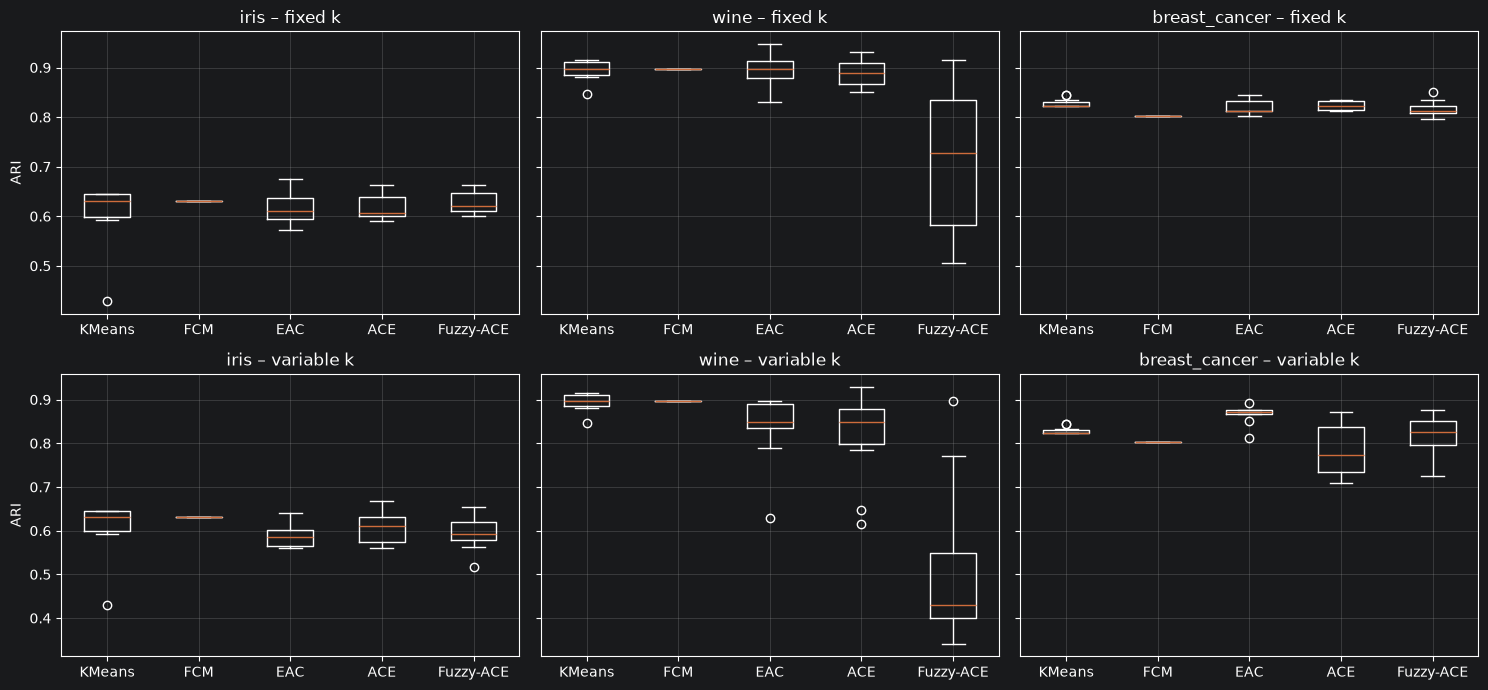

In [8]:
# Spread of the 10 runs per method
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey="row")
for r, setting in enumerate(["fixed", "variable"]):
    for c, key in enumerate(DATASETS):
        sub = raw[(raw.setting == setting) & (raw.dataset == key)]
        axes[r, c].boxplot([sub[sub.method == m]["ari"] for m in METHODS], tick_labels=list(METHODS))
        axes[r, c].set_title(f"{key} – {setting} k")
        axes[r, c].grid(alpha=0.3)
    axes[r, 0].set_ylabel("ARI")
plt.tight_layout()

## 5. Statistical tests (Iman–Davenport, Nemenyi, CD diagrams)

In [9]:
results = run_statistical_tests(str(exp_dir), alpha=0.1)
pd.read_csv(exp_dir / "statistics" / "tests_summary.csv")

,setting,metric,N,k,friedman_chi2,friedman_p,iman_davenport_F,iman_davenport_p,reject_h0,CD,best_method,significant_pairs,rank_FCM,rank_ACE,rank_EAC,rank_KMeans,rank_Fuzzy-ACE
0,fixed,ari,3,5,1.0667,0.8995,0.1951,0.9341,False,3.1746,FCM,NaN,2.3333,3.0000,3.0000,3.0000,3.6667
1,fixed,nmi,3,5,0.8000,0.9384,0.1429,0.9612,False,3.1746,EAC,NaN,2.6667,3.0000,2.6667,3.0000,3.6667
2,variable,ari,3,5,4.8000,0.3084,1.3333,0.3370,False,3.1746,FCM,NaN,2.0000,4.0000,3.0000,2.0000,4.0000
3,variable,nmi,3,5,3.4667,0.4830,0.8125,0.5512,False,3.1746,EAC,NaN,2.3333,3.3333,2.3333,2.6667,4.3333


## 6. α₂ grid search

Stages 1–2 are computed once per run, Stage 3 is repeated for α₂ ∈ {0.5, …, 0.9}.


In [11]:
grid_cfg = ExperimentConfig(name="notebook_alpha2", datasets=DATASETS, settings=["fixed"],
                            methods=["ACE", "Fuzzy-ACE"], n_runs=10, n_jobs=-1, results_dir=str(RESULTS_DIR))
grid_raw = run_alpha2_grid_search(grid_cfg, alpha_2_values=[0.5, 0.6, 0.7, 0.8, 0.9], verbose=False)
grid_dir = RESULTS_DIR / "notebook_alpha2"
pd.read_csv(grid_dir / "stability.csv").query("metric == 'ari'")

,setting,dataset,method,metric,best_alpha_2,best,worst,range,at_0.7
0,fixed,breast_cancer,ACE,ari,0.5,0.8232,0.8232,0.0,0.8232
2,fixed,breast_cancer,Fuzzy-ACE,ari,0.5,0.8168,0.8168,0.0,0.8168
4,fixed,iris,ACE,ari,0.5,0.6193,0.6193,0.0,0.6193
6,fixed,iris,Fuzzy-ACE,ari,0.5,0.6262,0.6262,0.0,0.6262
8,fixed,wine,ACE,ari,0.5,0.8904,0.8904,0.0,0.8904
10,fixed,wine,Fuzzy-ACE,ari,0.5,0.7099,0.7099,0.0,0.7099


## 7. Where the results are stored

In [13]:
for d in [exp_dir, grid_dir]:
    print(d.relative_to(ROOT))
    for p in sorted(d.rglob("*")):
        if p.is_file():
            print("   ", p.relative_to(d))

results\notebook_test
    config.json
    predicted_labels.csv
    raw_results.csv
    statistics\cd_diagrams\cd_ari_fixed.png
    statistics\cd_diagrams\cd_ari_variable.png
    statistics\cd_diagrams\cd_nmi_fixed.png
    statistics\cd_diagrams\cd_nmi_variable.png
    statistics\ranks_ari_fixed.csv
    statistics\ranks_ari_variable.csv
    statistics\ranks_nmi_fixed.csv
    statistics\ranks_nmi_variable.csv
    statistics\tests.json
    statistics\tests_summary.csv
    summary.csv
    tables\ari_fixed.csv
    tables\ari_fixed_means.csv
    tables\ari_variable.csv
    tables\ari_variable_means.csv
    tables\nmi_fixed.csv
    tables\nmi_fixed_means.csv
    tables\nmi_variable.csv
    tables\nmi_variable_means.csv
results\notebook_alpha2
    average_ranks.csv
    config.json
    figures\alpha2_ACE_fixed.png
    figures\alpha2_Fuzzy-ACE_fixed.png
    raw_results.csv
    stability.csv
    summary.csv
